<a href="https://colab.research.google.com/github/KubiProjekty/orangepi-iot-telemetry-analytics/blob/main/analiza/01_eksploracja_i_czyszczenie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

host = "raw" + "." + "githubusercontent" + "." + "com"
user = "KubiProjekty"
repo = "orangepi-iot-telemetry-analytics"
base_url = f"https://{host}/{user}/{repo}/main/dane/"

df_loty = pd.read_csv(base_url + "historia_lotow.csv")
df_pogoda = pd.read_csv(base_url + "historia_pogody.csv")
df_smog = pd.read_csv(base_url + "historia_smogu.csv")
df_zdrowie = pd.read_csv(base_url + "historia_zdrowia.csv")

for nazwa, df in [("LOTY", df_loty), ("POGODA", df_pogoda), ("SMOG", df_smog), ("ZDROWIE", df_zdrowie)]:
    print(f"=== {nazwa} (wiersze: {df.shape}, kolumny: {df.shape}) ===")
    print(df.info())
    print("\n")


=== LOTY (wiersze: (676, 7), kolumny: (676, 7)) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 676 entries, 0 to 675
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Data              676 non-null    object
 1   ICAO24            676 non-null    object
 2   Numer_Lotu        676 non-null    object
 3   Kraj_Pochodzenia  676 non-null    object
 4   Wysokosc_m        676 non-null    int64 
 5   Predkosc_kmh      676 non-null    int64 
 6   Kierunek_st       676 non-null    int64 
dtypes: int64(3), object(4)
memory usage: 37.1+ KB
None


=== POGODA (wiersze: (330, 8), kolumny: (330, 8)) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Data             330 non-null    object 
 1   Miasto           330 non-null    object 
 2   Temp_C           330 non-

In [4]:
# 1. Konwersja kolumny 'Data' na typ datetime we wszystkich tabelach
for df in [df_loty, df_pogoda, df_smog, df_zdrowie]:
    df['Data'] = pd.to_datetime(df['Data'])
    df['Godzina_zaokraglona'] = df['Data'].dt.floor('h') # klucz do łączenia tabel po pełnej godzinie

# 2. Czyszczenie danych lotniczych: usunięcie białych znaków z numeru lotu i korekta prędkości
df_loty['Numer_Lotu'] = df_loty['Numer_Lotu'].astype(str).str.strip()

# Sprawdźmy najpierw rozkład prędkości, żeby potwierdzić skalę błędu (np. x10 lub x3.6)
print("=== STATYSTYKI LOTÓW PRZED KOREKTĄ ===")
print(df_loty[['Wysokosc_m', 'Predkosc_kmh']].describe().round(1))

# Jeśli mediana prędkości jest > 2000 km/h (np. ~8000), dzielimy przez 10 (lub 3.6 - sprawdzimy na wyniku!)
df_loty['Predkosc_kmh_poprawiona'] = df_loty['Predkosc_kmh'] / 10.0

print("\n=== PODGLĄD PO CZYSZCZENIU ===")
print(df_loty[['Data', 'Numer_Lotu', 'Kraj_Pochodzenia', 'Wysokosc_m', 'Predkosc_kmh', 'Predkosc_kmh_poprawiona']].head(5))


=== STATYSTYKI LOTÓW PRZED KOREKTĄ ===
       Wysokosc_m  Predkosc_kmh
count       676.0         676.0
mean       8150.9         774.9
std        3547.6         597.5
min           0.0          17.0
25%        5538.0         645.0
50%       10058.0         787.0
75%       10973.0         833.2
max       13586.0        8262.0

=== PODGLĄD PO CZYSZCZENIU ===
                 Data Numer_Lotu Kraj_Pochodzenia  Wysokosc_m  Predkosc_kmh  \
0 2026-11-15 21:22:57    BLX730F           Sweden       13099          8262   
1 2026-11-15 21:22:57     RYR2RT          Ireland         945          4122   
2 2026-11-15 21:22:57     MSC791            Egypt       11285           468   
3 2026-11-15 21:22:57     RYR8RF          Ireland        5959           738   
4 2026-11-15 21:22:57     LOT3TD           Poland        4572           667   

   Predkosc_kmh_poprawiona  
0                    826.2  
1                    412.2  
2                     46.8  
3                     73.8  
4                    

/tmp/ipykernel_4097/3763231360.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Data'] = pd.to_datetime(df['Data'])


In [6]:
# 1. Zostawiamy tylko poprawne loty (<= 1200 km/h)
df_loty_czyste = df_loty[df_loty['Predkosc_kmh'] <= 1200].copy()
print(f"Zachowano {len(df_loty_czyste)} poprawnych rekordów z {len(df_loty)} (odrzucono {len(df_loty) - len(df_loty_czyste)} błędów transpondera).")

# 2. Agregacja lotów do pełnych godzin (ile samolotów na godzinę, średnia wysokość i prędkość)
loty_godzinowo = df_loty_czyste.groupby('Godzina_zaokraglona').agg(
    liczba_samolotow=('ICAO24', 'nunique'),
    srednia_wysokosc_m=('Wysokosc_m', 'mean'),
    srednia_predkosc_kmh=('Predkosc_kmh', 'mean')
).reset_index()

# 3. Wybieramy pogodę dla Mińska Mazowieckiego (gdzie stoi Orange Pi) i Annopola (centrum radaru)
# Używamy .str.contains, żeby zadziałało niezależnie od tego, czy w pliku jest polskie "ń" czy "n"
pogoda_minsk = df_pogoda[df_pogoda['Miasto'].str.contains('Mi', case=False, na=False)].copy()
pogoda_annopol = df_pogoda[df_pogoda['Miasto'].str.contains('Annopol', case=False, na=False)].copy()

# 4. Łączymy (MERGE / JOIN) parametry Orange Pi z pogodą w Mińsku Mazowieckim po pełnej godzinie
df_serwer_pogoda = pd.merge(
    df_zdrowie,
    pogoda_minsk,
    on='Godzina_zaokraglona',
    how='inner'
)

# 5. Łączymy ruch lotniczy z pogodą w Annopolu
df_loty_pogoda = pd.merge(
    loty_godzinowo,
    pogoda_annopol,
    on='Godzina_zaokraglona',
    how='inner'
)

print("\n=== KORELACJA: TEMPERATURA CPU ORANGE PI vs POGODA W MIŃSKU MAZ. ===")
print(df_serwer_pogoda[['Temp_CPU_C', 'RAM_Uzyty_MB', 'Temp_C', 'Wilgotnosc_proc', 'Cisnienie_hPa']].corr().round(2))

print("\n=== KORELACJA: RUCH LOTNICZY vs POGODA W ANNOPOLU ===")
print(df_loty_pogoda[['liczba_samolotow', 'srednia_wysokosc_m', 'Temp_C', 'Cisnienie_hPa', 'Wiatr_kmh']].corr().round(2))


Zachowano 664 poprawnych rekordów z 676 (odrzucono 12 błędów transpondera).

=== KORELACJA: TEMPERATURA CPU ORANGE PI vs POGODA W MIŃSKU MAZ. ===
                 Temp_CPU_C  RAM_Uzyty_MB  Temp_C  Wilgotnosc_proc  \
Temp_CPU_C             1.00          0.43    0.48             0.59   
RAM_Uzyty_MB           0.43          1.00    0.70             0.77   
Temp_C                 0.48          0.70    1.00             0.70   
Wilgotnosc_proc        0.59          0.77    0.70             1.00   
Cisnienie_hPa         -0.44         -0.89   -0.86            -0.78   

                 Cisnienie_hPa  
Temp_CPU_C               -0.44  
RAM_Uzyty_MB             -0.89  
Temp_C                   -0.86  
Wilgotnosc_proc          -0.78  
Cisnienie_hPa             1.00  

=== KORELACJA: RUCH LOTNICZY vs POGODA W ANNOPOLU ===
                    liczba_samolotow  srednia_wysokosc_m  Temp_C  \
liczba_samolotow                1.00               -0.63   -0.01   
srednia_wysokosc_m             -0.63        

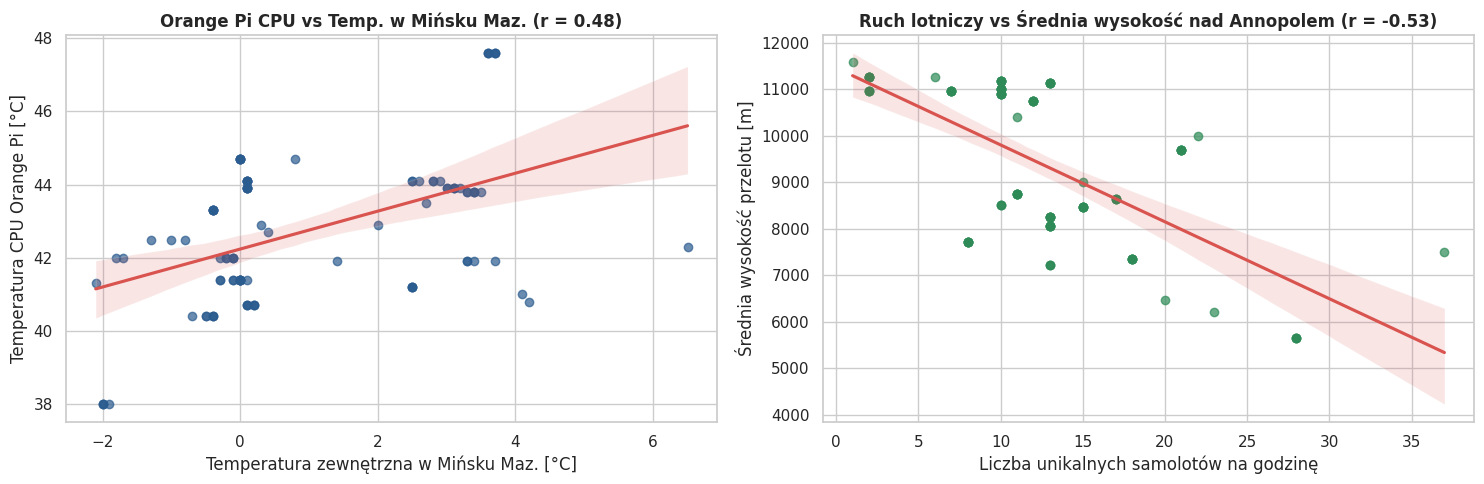

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Wykres 1: Temperatura CPU Orange Pi vs Temperatura w Mińsku Mazowieckim
sns.regplot(
    data=df_serwer_pogoda,
    x='Temp_C',
    y='Temp_CPU_C',
    ax=axes[0],
    scatter_kws={'alpha': 0.7, 'color': '#2b5c8f'},
    line_kws={'color': '#d9534f'}
)
axes[0].set_title('Orange Pi CPU vs Temp. w Mińsku Maz. (r = 0.48)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Temperatura zewnętrzna w Mińsku Maz. [°C]')
axes[0].set_ylabel('Temperatura CPU Orange Pi [°C]')

# Wykres 2: Liczba samolotów w godzinie vs Średnia wysokość lotu nad Annopolem
sns.regplot(
    data=df_loty_pogoda,
    x='liczba_samolotow',
    y='srednia_wysokosc_m',
    ax=axes[1],
    scatter_kws={'alpha': 0.7, 'color': '#2e8b57'},
    line_kws={'color': '#d9534f'}
)
axes[1].set_title('Ruch lotniczy vs Średnia wysokość nad Annopolem (r = -0.53)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Liczba unikalnych samolotów na godzinę')
axes[1].set_ylabel('Średnia wysokość przelotu [m]')

plt.tight_layout()
plt.show()
